# Buy now, rent later: a two-stage server farm

The newsvendor in this folder orders papers before it knows demand and then sells or scraps. This
is the same structure with more moving parts. You buy CPUs, GPUs and TPUs now, under a budget and a
floor-space limit. Then demand for each kind of compute arrives, and whatever your own machines
cannot cover you rent from a cloud provider at a higher price.

The purchase is the **first stage**: one decision, no scenario index. The rentals are the **second
stage**, or recourse: one decision per scenario, made after that scenario's demand is known.

## Setup: where the package lives

This notebook builds its model by hand and then checks it against `orteach`, the package in `src/`.
Run from a clone of the repository, `../../src` is right there. On Colab there is no clone until
this cell makes one, and no `gurobipy` until it installs it. Nothing here needs a secret.

In [1]:
import os, subprocess, sys

REPO_URL = "https://github.com/sear-labs/teaching-code"
REF = "v1.0.1"                               # the release this notebook ships in: Colab clones THIS

try:
    import google.colab                      # noqa: F401 - succeeds only on Colab
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

if ON_COLAB:
    if not os.path.isdir("/content/teaching-code"):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "--branch", REF, REPO_URL, "/content/teaching-code"], check=True)
    os.chdir("/content/teaching-code/notebooks/07_stochastic_and_newsvendor")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "gurobipy>=11,<14"], check=True)

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "src")))
try:
    import orteach                            # noqa: F401
except ImportError:
    raise SystemExit("orteach not found: run this notebook from its own folder inside the repository, "
                     "so that ../../src exists.")
root = os.path.abspath(os.path.join("..", ".."))
print("package:", os.path.relpath(os.path.dirname(orteach.__file__), root))

package: src\orteach


## Licence setup

Nothing here needs a key: `pip install gurobipy` ships a size-limited licence, and this model (three
purchase variables and three rentals per scenario) sits well inside it. A machine with its own
licence file uses that instead, and on Colab three secrets read from the key icon in the left
sidebar are used when they are there. The environment starts silent, so no licence number lands in
an output cell.

In [2]:
import gurobipy as gp
from gurobipy import GRB

env = gp.Env(empty=True)
env.setParam("OutputFlag", 0)        # start silent: the licence banner, and its licence number, stay out of the outputs
try:
    from google.colab import userdata
    try:
        env.setParam("WLSACCESSID", userdata.get("GRB_WLSACCESSID"))
        env.setParam("WLSSECRET",   userdata.get("GRB_WLSSECRET"))
        env.setParam("LICENSEID",   int(userdata.get("GRB_LICENSEID")))
        licence = "Colab Secrets (WLS)"
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        licence = "the size-limited licence pip ships"     # no key needed; see the note above
except ImportError:
    licence = "local gurobi.lic"
env.start()
print("licence:", licence)

licence: local gurobi.lic


## The machines and the scenarios are tables

Each machine type has a price, the floor space it takes, and the price of renting one unit of the
same compute from the cloud instead. Each of the 50 demand scenarios says how much of each kind of
compute is needed. Both are instance data, so they live in `data/raw/` and the package reads the
same files. The budget and the floor space are knobs: one number each, written out here.

In [3]:
from statistics import mean
from orteach import tolerance
from orteach.serverfarm import load_machines, load_demand

BUDGET = 1000
SPACE = 100

machines = load_machines()
demand = load_demand()
T = machines.types
K = len(demand)

print(f"budget {BUDGET}, floor space {SPACE}, {K} scenarios")
print(f"{'machine':8} {'buy':>5} {'space':>6} {'cloud':>6}   demand: mean   min    max")
for t in T:
    col = [d[t] for d in demand]
    print(f"{t:8} {machines.purchase[t]:5.0f} {machines.space[t]:6.0f} {machines.cloud[t]:6.0f}"
          f"           {mean(col):6.1f} {min(col):6.1f} {max(col):6.1f}")

budget 1000, floor space 100, 50 scenarios
machine    buy  space  cloud   demand: mean   min    max
cpu          6      1      7             69.4   44.6   89.9
gpu         14      5     18              8.3    4.2   13.4
tpu         27      3     30             14.4    7.8   21.9


## The first stage

Three integer variables, one per machine type, and two limits on them. The limits are written out
term by term, because which one binds is the first thing to look at. Predict now, before anything
is solved: will the purchase run out of money first, or out of floor space?

In [4]:
m = gp.Model("server farm", env=env)
tolerance.apply(m)
buy = m.addVars(T, vtype=GRB.INTEGER, name="buy")

budget = m.addConstr(machines.purchase["cpu"] * buy["cpu"] + machines.purchase["gpu"] * buy["gpu"]
                     + machines.purchase["tpu"] * buy["tpu"] <= BUDGET, name="budget")
space = m.addConstr(machines.space["cpu"] * buy["cpu"] + machines.space["gpu"] * buy["gpu"]
                    + machines.space["tpu"] * buy["tpu"] <= SPACE, name="space")
m.update()
print(m.getRow(budget), "<=", BUDGET)
print(m.getRow(space), "<=", SPACE)

6.0 buy[cpu] + 14.0 buy[gpu] + 27.0 buy[tpu] <= 1000
buy[cpu] + 5.0 buy[gpu] + 3.0 buy[tpu] <= 100


## The second stage

One rental variable per scenario and machine type, and one covering constraint for each: what you
own plus what you rent must meet that scenario's demand. The constraint is identical across
scenarios except for the demand number, which is what `addConstrs` over `k` is for. The three
machine types are written out, so you can see that each scenario has its own rentals but shares
the single `buy`.

In [5]:
rent = m.addVars(K, T, vtype=GRB.INTEGER, name="rent")
m.addConstrs((buy["cpu"] + rent[k, "cpu"] >= demand[k]["cpu"] for k in range(K)), name="cover_cpu")
m.addConstrs((buy["gpu"] + rent[k, "gpu"] >= demand[k]["gpu"] for k in range(K)), name="cover_gpu")
m.addConstrs((buy["tpu"] + rent[k, "tpu"] >= demand[k]["tpu"] for k in range(K)), name="cover_tpu")
m.update()
print(m.NumVars, "variables (all integer:", m.NumIntVars, "),", m.NumConstrs, "constraints")

153 variables (all integer: 153 ), 152 constraints


The objective is what you pay for the machines, plus the cloud bill averaged over the scenarios,
each equally likely.

In [6]:
purchase_cost = gp.quicksum(machines.purchase[t] * buy[t] for t in T)
cloud_bill = gp.quicksum(machines.cloud[t] * rent[k, t] for k in range(K) for t in T) / K
m.setObjective(purchase_cost + cloud_bill, GRB.MINIMIZE)

Predict before solving: will the farm buy any GPUs, given that renting one is only a little dearer
than owning one?

In [7]:
m.optimize()
hand_buy = {t: round(buy[t].X) for t in T}
hand_cost = m.ObjVal
print("buy", hand_buy, f"   expected cost {hand_cost:.4f}   MIP gap {m.MIPGap:.1e}")
print(f"money spent {purchase_cost.getValue():.0f} of {BUDGET}    floor space used "
      f"{sum(machines.space[t] * hand_buy[t] for t in T):.0f} of {SPACE}")

buy {'cpu': 51, 'gpu': 5, 'tpu': 8}    expected cost 1000.5400   MIP gap 0.0e+00
money spent 592 of 1000    floor space used 100 of 100


Was your prediction about the binding limit right? If one limit is slack, what is the other one
costing you, and how would you find out?

## The recourse

The purchase is the same in every scenario; the rentals are not. Look at both together.

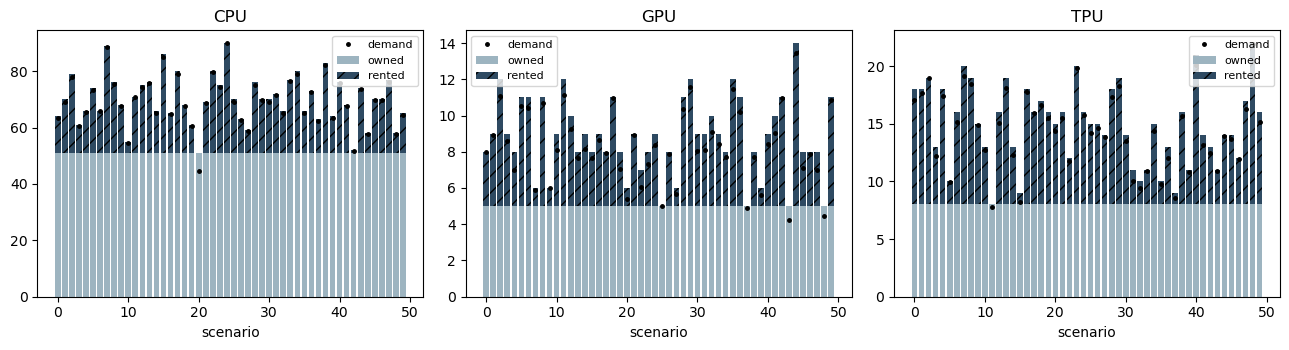

Figure: CPU panel, 51 owned in every scenario; rentals range from 0 to 39, with none needed in 1 of 50 scenarios.
Figure: GPU panel, 5 owned in every scenario; rentals range from 0 to 9, with none needed in 4 of 50 scenarios.
Figure: TPU panel, 8 owned in every scenario; rentals range from 0 to 14, with none needed in 1 of 50 scenarios.


In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, t in zip(axes, T):
    rented = [rent[k, t].X for k in range(K)]
    ax.bar(range(K), [hand_buy[t]] * K, color="#9DB4C0", label="owned")
    ax.bar(range(K), rented, bottom=[hand_buy[t]] * K, color="#2E4A62", hatch="//", label="rented")
    ax.plot(range(K), [d[t] for d in demand], "k.", ms=5, label="demand")
    ax.set_title(t.upper())
    ax.set_xlabel("scenario")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for t in T:
    rented = [round(rent[k, t].X) for k in range(K)]
    print(f"Figure: {t.upper()} panel, {hand_buy[t]} owned in every scenario; rentals range from {min(rented)} to "
          f"{max(rented)}, with none needed in {rented.count(0)} of {K} scenarios.")

## Planning for the average

The tempting shortcut: replace the 50 scenarios by their average and solve once. Build that model
(one scenario, the mean demand), then take its purchase and cost it honestly against all 50
scenarios. A scenario's rentals, once the purchase is fixed, are just the shortfall rounded up.

In [9]:
import math
avg = {t: mean(d[t] for d in demand) for t in T}

ma = gp.Model("plan for the average", env=env)
tolerance.apply(ma)
a_buy = ma.addVars(T, vtype=GRB.INTEGER, name="buy")
a_rent = ma.addVars(T, vtype=GRB.INTEGER, name="rent")
ma.addConstr(gp.quicksum(machines.purchase[t] * a_buy[t] for t in T) <= BUDGET, name="budget")
ma.addConstr(gp.quicksum(machines.space[t] * a_buy[t] for t in T) <= SPACE, name="space")
ma.addConstrs((a_buy[t] + a_rent[t] >= avg[t] for t in T), name="cover")
ma.setObjective(gp.quicksum(machines.purchase[t] * a_buy[t] + machines.cloud[t] * a_rent[t] for t in T), GRB.MINIMIZE)
ma.optimize()
avg_buy = {t: round(a_buy[t].X) for t in T}

avg_rent = [{t: max(0, math.ceil(d[t] - avg_buy[t] - tolerance.FEASIBILITY_ATOL)) for t in T} for d in demand]
avg_cost = (sum(machines.purchase[t] * avg_buy[t] for t in T)
            + sum(machines.cloud[t] * r[t] for r in avg_rent for t in T) / K)
print("planning for the average buys", avg_buy, f"  objective it reports {ma.ObjVal:.2f}")
print(f"costed against the {K} scenarios: {avg_cost:.4f}   versus the stochastic plan {hand_cost:.4f}")
print(f"value of the stochastic solution {avg_cost - hand_cost:.4f}")

planning for the average buys {'cpu': 55, 'gpu': 0, 'tpu': 15}   objective it reports 1002.00
costed against the 50 scenarios: 1039.1200   versus the stochastic plan 1000.5400
value of the stochastic solution 38.5800


The average plan's own objective and its honest cost are different numbers. Why is the honest one
higher, and which machine type does the average plan get most wrong?

---

# Now the streamlined version

The package holds the same model once, written in matrix form with `addMVar` (the form IE 5301's
code uses): `serverfarm.solve_two_stage`, `serverfarm.solve_mean_value` for the shortcut costed
honestly, and `serverfarm.score_plan` for any purchase decided some other way.

In [10]:
from orteach import serverfarm as sf
from orteach.tolerance import AGREEMENT_RTOL, rel_diff

pkg = sf.solve_two_stage(machines, demand, BUDGET, SPACE, env=env)
pkg_avg = sf.solve_mean_value(machines, demand, BUDGET, SPACE, env=env)
print("stochastic   ", pkg.buy, f"{pkg.expected_cost:.4f}")
print("average plan ", pkg_avg.buy, f"{pkg_avg.expected_cost:.4f}")

stochastic    {'cpu': 51, 'gpu': 5, 'tpu': 8} 1000.5400
average plan  {'cpu': 55, 'gpu': 0, 'tpu': 15} 1039.1200


## The agreement assertion

Two ways of writing the model, one answer. The optimal purchase is unique (`tests/test_serverfarm.py`
checks it by minimising and maximising each machine count over every optimal plan), so the purchases
are compared whole, along with both costs and the value of the stochastic solution.

In [11]:
checks = [("expected cost", hand_cost, pkg.expected_cost),
          ("average plan, costed", avg_cost, pkg_avg.expected_cost),
          ("value of the stochastic solution", avg_cost - hand_cost, pkg_avg.expected_cost - pkg.expected_cost)]
for t in T:
    checks.append((f"buy {t}", hand_buy[t], pkg.buy[t]))
    checks.append((f"average plan buys {t}", avg_buy[t], pkg_avg.buy[t]))

worst = max(rel_diff(h, k) for _, h, k in checks)
print(f"{len(checks)} comparisons")
for name, hand, packaged in checks[:4]:
    print(f"  {name:34} hand {hand:10.4f}   package {packaged:10.4f}   rel {rel_diff(hand, packaged):.2e}")
print("  ...")
assert worst < AGREEMENT_RTOL, f"notebook and package disagree by {worst:.2e}"
print(f"\nnotebook and package agree to {worst:.1e}")

9 comparisons
  expected cost                      hand  1000.5400   package  1000.5400   rel 0.00e+00
  average plan, costed               hand  1039.1200   package  1039.1200   rel 0.00e+00
  value of the stochastic solution   hand    38.5800   package    38.5800   rel 0.00e+00
  buy cpu                            hand    51.0000   package    51.0000   rel 0.00e+00
  ...

notebook and package agree to 0.0e+00


---

## Where to take this next

- Raise `SPACE` to 120. Predict what the farm buys with the extra room, then check.
- Make the rentals continuous instead of integer (drop `vtype` on `rent`). Does the purchase change,
  and what does the space constraint's dual now say a square metre is worth?
- The demand table was generated from a recorded seed (`serverfarm.DEMAND_SEED`). Regenerate it with
  seed 7 and 40 scenarios and re-solve. Is the optimal purchase still unique?